# 02 - Feature engineering

The actual code lives in `src/features.py`, this notebook just runs it and checks the output.

Main points:
- transactions are rolled up to **one row per customer** before joining, otherwise each loan gets duplicated
- `approval_status`, `approved_amount`, `decision_date`, `disbursed_flag` are dropped (only known after the decision)
- email/phone/names never get loaded into the feature table
- only disbursed loans are used for training since that's where `loan_default` is known

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
from features import load_tables, transaction_features, build_features, NUMERIC, CATEGORICAL, TARGET

customers, credit, loans, txns = load_tables()
txn_feats = transaction_features(txns)
print(txn_feats.shape, "- one row per customer:", txn_feats["customer_id"].is_unique)
txn_feats.head()

(5000, 8) - one row per customer: True


,customer_id,total_inflow,total_outflow,emi_outflow,avg_balance,txn_count,net_cash_flow,inflow_outflow_ratio
0,CUST100001,0.00,18570.47,0.00,39151.317500,4,-18570.47,0.000000
1,CUST100002,0.00,8544.61,0.00,16165.722500,4,-8544.61,0.000000
2,CUST100003,14192.69,25230.16,1278.10,20026.796364,11,-11037.47,0.562529
3,CUST100004,73985.80,27026.15,7280.57,44215.130833,12,46959.65,2.737563
4,CUST100005,0.00,43285.20,0.00,46464.708333,6,-43285.20,0.000000


In [3]:
features = build_features(customers, credit, loans, txns)
print("all applications:", features.shape, "| unique ids:", features["application_id"].is_unique)

df = features[features[TARGET].notna()].copy()
df[TARGET] = df[TARGET].astype(int)
print("disbursed (modelling set):", df.shape)
print(len(NUMERIC), "numeric +", len(CATEGORICAL), "categorical features")

all applications: (7500, 36) | unique ids: True
disbursed (modelling set): (3403, 36)
28 numeric + 5 categorical features


## Missing values after the joins

In [4]:
miss = df.isna().sum()
miss[miss > 0]

inflow_outflow_ratio    3
dtype: int64

Only `inflow_outflow_ratio` has a few gaps (customers with no debits). The pipeline fills
these with the median.

`tenure_years` gets clipped at 0 because 418 loans are dated before the customer's
`customer_since` date, which looks like a data quirk.

## New features vs default

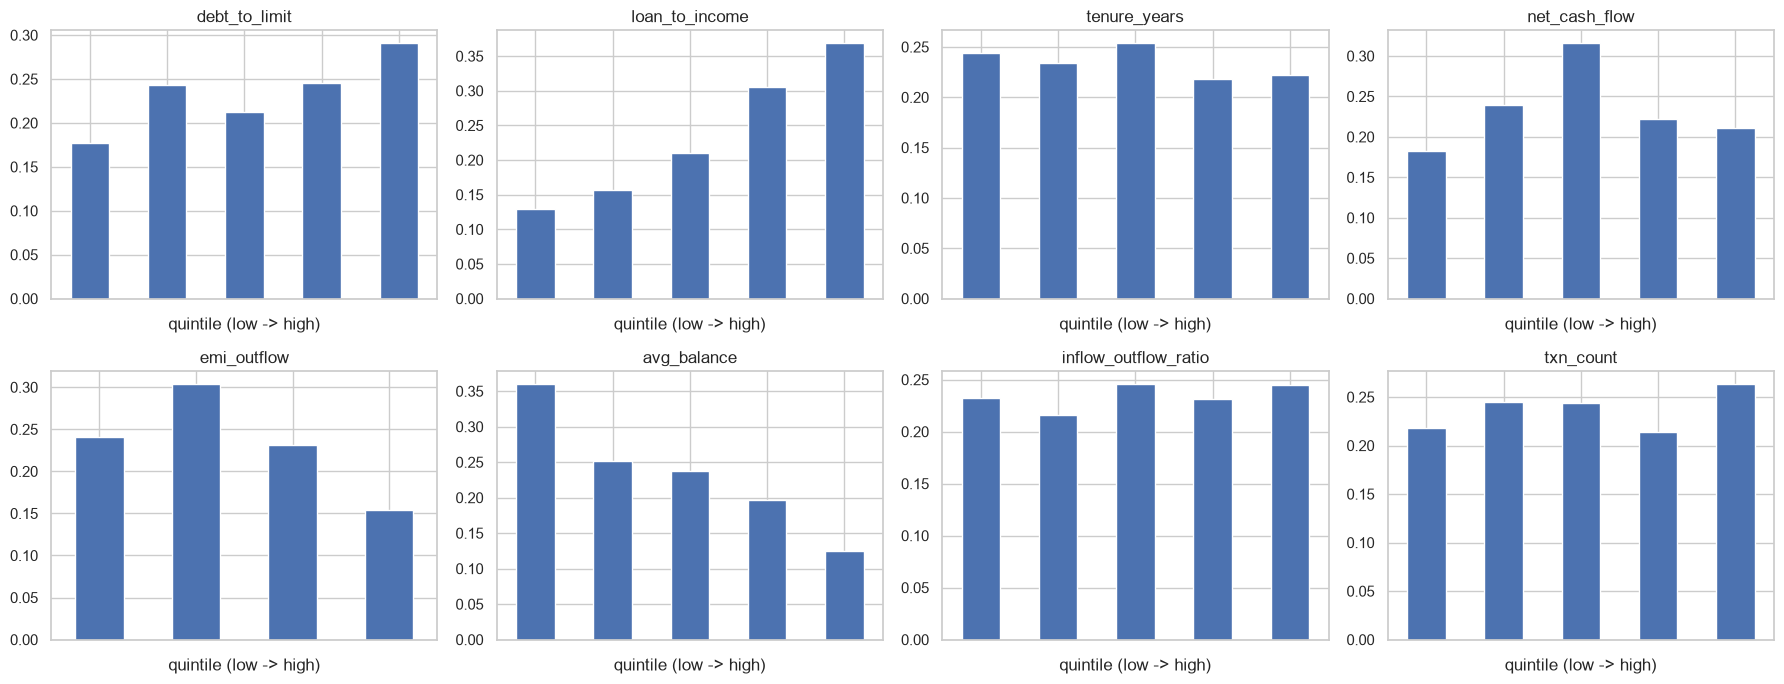

In [5]:
new_feats = ["debt_to_limit", "loan_to_income", "tenure_years", "net_cash_flow",
             "emi_outflow", "avg_balance", "inflow_outflow_ratio", "txn_count"]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, new_feats):
    q = pd.qcut(df[col], 5, duplicates="drop")
    df.groupby(q, observed=True)[TARGET].mean().plot.bar(ax=ax, title=col)
    ax.set_xticklabels([])
    ax.set_xlabel("quintile (low -> high)")
plt.tight_layout()

In [6]:
df[new_feats + [TARGET]].corr()[TARGET].drop(TARGET).sort_values().round(3)

avg_balance            -0.155
emi_outflow            -0.089
tenure_years           -0.020
net_cash_flow          -0.002
txn_count               0.007
inflow_outflow_ratio    0.023
debt_to_limit           0.088
loan_to_income          0.175
Name: loan_default, dtype: float64

`loan_to_income` and `avg_balance` are the useful ones here (lower balance -> more defaults).
The other transaction features are pretty weak on their own, leaving them in for now
and the tree models can decide.

## Repeat borrowers

In [7]:
df.groupby("customer_id").size().value_counts().sort_index()

1    1500
2     583
3     176
4      43
5       5
6       2
Name: count, dtype: int64

About 800 customers have more than one disbursed loan, and their bureau / transaction
features are identical across those loans. So the train/test split is grouped by
`customer_id` (still stratified on the target) to stop the same person ending up on both sides.

One more thing to note: the bureau snapshot is from June 2024 and transactions are Jan-Jun 2024,
so for older loans these are measured *after* the loan was given. That's how the dataset
is set up, will mention it in the model card.

## Preprocessing check

In [8]:
from features import make_preprocessor

prep = make_preprocessor(scale=True)
X = prep.fit_transform(df[NUMERIC + CATEGORICAL])
print("encoded shape:", X.shape)
prep.get_feature_names_out()[-24:]

encoded shape: (3403, 52)


array(['cat__loan_type_Auto', 'cat__loan_type_Business',
       'cat__loan_type_Education', 'cat__loan_type_Gold',
       'cat__loan_type_Home', 'cat__loan_type_Personal',
       'cat__employment_type_Business Owner',
       'cat__employment_type_Retired', 'cat__employment_type_Salaried',
       'cat__employment_type_Self-Employed',
       'cat__employment_type_Unemployed', 'cat__education_Diploma',
       'cat__education_Graduate', 'cat__education_High School',
       'cat__education_Post Graduate',
       'cat__education_Professional Degree',
       'cat__residence_type_Family Owned',
       'cat__residence_type_Mortgaged', 'cat__residence_type_Owned',
       'cat__residence_type_Rented', 'cat__marital_status_Divorced',
       'cat__marital_status_Married', 'cat__marital_status_Single',
       'cat__marital_status_Widowed'], dtype=object)